# Smog Tomorrow? A day-ahead PM2.5 warning for Almaty

**Track: AI + Climate** · Veritas AI International High School Hackathon 2026

**Who is it for?** A PE (physical education) teacher at a school in Almaty, Kazakhstan.
Every evening they have to decide whether tomorrow's lesson can be held outdoors.
Almaty sits in a basin under the mountains, and in winter coal smoke and car exhaust get trapped over the city.

**What goes in, what comes out?**
In: the PM2.5 measurements up to 18:00 today + the weather forecast for tomorrow.
Out: tomorrow's average PM2.5, a likely range, and a clear "outdoors / indoors" advice with the main reasons —
and, one step further, a weekly plan that moves the outdoor lessons to the cleanest days (section 8).

**How to read this notebook.** It runs from top to bottom in about a minute, needs no API key and no GPU.
Every number in the write-up is printed by the code below. The steps are:

1. Load the data → 2. Build the inputs and the target → 3. Split by date → 4. Simple baselines →
5. Choose a model using past winters only → 6. One final test on the newest data →
7. Check with real weather forecasts → 8. Let the forecast move the lessons →
9. Two checks added later (a global model, school hours) → 10. A year the model never saw (2026, another sensor) →
11. Where it fails → 12. Why the model says what it says → 13. Demo

In [1]:
import json
import os
import platform
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# On Google Colab the data files are not there yet, so we copy the public repository first.
REPO, BRANCH = "https://github.com/yk59m2cmhw-hash/c.git", "claude/epic-goldberg-ya2g09"
if not os.path.exists("data/raw/almaty_pm25_hourly_openaq8876.csv"):
    subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO, "smog_repo"], check=True)
    os.chdir("smog_repo")

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 2)

# ---- settings that define the task (fixed before any model was trained)
ISSUE_HOUR = 18            # the forecast is made at 18:00 Almaty time
MIN_HOURS_PER_DAY = 18     # a daily average needs at least 18 of 24 hourly values
ALERT_LEVEL = 35.4         # µg/m³: above this the US EPA calls the air "Unhealthy for Sensitive Groups" or worse
MISS_COST = 2.0            # a missed smog day counts twice as much as a false alarm
SPLIT = dict(train_end="2023-09-30", val_start="2023-10-01", val_end="2024-09-30", test_start="2024-10-01")
RESULTS_DIR = "results"
os.makedirs(f"{RESULTS_DIR}/figures", exist_ok=True)

# ---- one look for every chart
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#d03b3b"       # our model, the persistence baseline, the alert level
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "legend.frameon": False,
})

## 1. Load the data

**Air:** hourly PM2.5 from the reference-grade monitor "Almaty" (OpenAQ location 8876, data provider AirNow,
licence: US Public Domain), April 2020 – November 2025, downloaded from the public OpenAQ archive.
The archive for this monitor ends on 14 November 2025.

**Weather:** hourly values from the Open-Meteo Historical Weather API (ECMWF IFS 9 km model, licence CC BY 4.0)
for the city and for a mountain grid cell above it (2,927 m).

Kazakhstan moved its clocks from UTC+6 to UTC+5 on 1 March 2024. We handle this by hand so that
"18:00" and "tomorrow" always mean Almaty wall-clock time.

In [2]:
TZ_SWITCH_UTC = pd.Timestamp("2024-02-29 18:00")     # 00:00 on 1 March 2024 in Almaty


def utc_to_almaty(utc):
    """UTC timestamps -> Almaty wall-clock time (UTC+6 before the 2024 switch, UTC+5 after)."""
    utc = pd.to_datetime(utc)
    return utc + pd.to_timedelta(np.where(utc < TZ_SWITCH_UTC, 6, 5), unit="h")


def load_pm_hourly(path):
    """Hourly PM2.5, indexed by the local start time of each hour. Missing hours stay as NaN."""
    raw = pd.read_csv(path)
    utc = pd.to_datetime(raw["utc_start"], utc=True).dt.tz_localize(None)
    s = pd.Series(raw["pm25"].to_numpy(), index=utc_to_almaty(utc))
    s = s[(s >= 0) & (s <= 2000)]              # remove impossible values (sensor glitches)
    s = s.groupby(level=0).mean()              # one hour repeats on the night the clocks changed
    return s.asfreq("h")


def load_weather_hourly(path):
    w = pd.read_csv(path)
    w.index = utc_to_almaty(w.pop("utc_time"))
    return w[~w.index.duplicated()]


pm_hourly = load_pm_hourly("data/raw/almaty_pm25_hourly_openaq8876.csv")
city_hourly = load_weather_hourly("data/raw/weather_city_ifs.csv")
mountain_hourly = load_weather_hourly("data/raw/weather_mountain_ifs.csv")

print(f"PM2.5 : {pm_hourly.index.min()} .. {pm_hourly.index.max()} | {int(pm_hourly.notna().sum()):,} valid hours "
      f"({pm_hourly.notna().mean():.0%} of all hours in the period)")
print(f"Weather: {city_hourly.index.min()} .. {city_hourly.index.max()} | {len(city_hourly):,} hours, "
      f"{int(city_hourly.isna().sum().drop('snow_depth', errors='ignore').drop('boundary_layer_height', errors='ignore').sum())} missing values in the columns we use")

PM2.5 : 2020-04-09 21:00:00 .. 2025-11-14 15:00:00 | 34,476 valid hours (70% of all hours in the period)
Weather: 2020-04-01 06:00:00 .. 2025-11-16 04:00:00 | 49,319 hours, 0 missing values in the columns we use


## 2. Build the target and the inputs

* **Target:** the average PM2.5 of the next calendar day (D+1).
* **Forecast time:** 18:00 on day D. From the air monitor we may only use hours that ended by 18:00.
* **Weather for tomorrow:** daily summaries of day D+1 from the weather model. In real life this would be the
  weather *forecast*; section 7 repeats the test with real archived forecasts.

In [3]:
def daily_mean(pm):
    """Average of each calendar day; NaN if fewer than MIN_HOURS_PER_DAY hourly values exist."""
    g = pm.groupby(pm.index.normalize())
    return g.mean().where(g.count() >= MIN_HOURS_PER_DAY)


def pm_inputs(pm):
    """What the air monitor tells us at 18:00 on each day D (index = D)."""
    last_hour = pm.index.hour == ISSUE_HOUR - 1          # the hour 17:00-18:00 is the last one we may use

    def at_issue(series):
        out = series[last_hour]
        out.index = out.index.normalize()
        return out

    f = pd.DataFrame({
        "pm_last24": at_issue(pm.rolling(24, min_periods=18).mean()),     # average of the 24 hours before 18:00
        "pm_max24": at_issue(pm.rolling(24, min_periods=18).max()),
        "pm_last6": at_issue(pm.rolling(6, min_periods=4).mean()),        # 12:00-18:00 today
        "pm_last72": at_issue(pm.rolling(72, min_periods=36).mean()),     # last three days
    })
    f["pm_prev24"] = f["pm_last24"].shift(1, freq="D")                    # the 24 hours before that
    night = pm[pm.index.hour < 8]
    g = night.groupby(night.index.normalize())
    f["pm_night"] = g.mean().where(g.count() >= 5)                        # 00:00-08:00 today
    for col in ["pm_last6", "pm_last72", "pm_prev24", "pm_night"]:         # small gaps: fall back to the 24 h average
        f[col] = f[col].fillna(f["pm_last24"])
    f["pm_trend"] = np.log1p(f["pm_last24"]) - np.log1p(f["pm_prev24"])   # rising or falling?
    return f


def city_daily(c):
    """Daily summaries of hourly city weather (index = local calendar day). Only complete days are kept."""
    day = c.index.normalize()
    angle = np.deg2rad(c["wind_direction_10m"])
    u, v = -c["wind_speed_10m"] * np.sin(angle), -c["wind_speed_10m"] * np.cos(angle)
    d = pd.DataFrame({
        "t_mean": c["temperature_2m"].groupby(day).mean(),
        "t_min": c["temperature_2m"].groupby(day).min(),
        "wind_mean": c["wind_speed_10m"].groupby(day).mean(),
        "wind_max": c["wind_speed_10m"].groupby(day).max(),
        "gust_max": c["wind_gusts_10m"].groupby(day).max(),
        "wind_u": u.groupby(day).mean(),                    # west-east part of the wind
        "wind_v": v.groupby(day).mean(),                    # south-north part of the wind
        "precip": c["precipitation"].groupby(day).sum(),
        "snowfall": c["snowfall"].groupby(day).sum(),
        "humidity": c["relative_humidity_2m"].groupby(day).mean(),
        "pressure": c["surface_pressure"].groupby(day).mean(),
        "cloud": c["cloud_cover"].groupby(day).mean(),
        "sun": c["shortwave_radiation"].groupby(day).mean(),
    })
    return d[c["temperature_2m"].groupby(day).count() >= 24]


def inversion_daily(city, mountain):
    """How much colder the mountain cell (2,927 m) is than the city (~800 m).
    Usually about 10-12 °C colder. When the gap shrinks, warm air sits like a lid on the city (an inversion)."""
    gap = (mountain["temperature_2m"] - city["temperature_2m"]).dropna()
    night = gap[gap.index.hour < 9]
    return pd.DataFrame({
        "mtn_minus_city": gap.groupby(gap.index.normalize()).mean(),
        "mtn_minus_city_night": night.groupby(night.index.normalize()).mean(),
        "mtn_wind": mountain["wind_speed_10m"].groupby(mountain.index.normalize()).mean(),
    })


PM_COLS = ["pm_last24", "pm_max24", "pm_last6", "pm_last72", "pm_prev24", "pm_night", "pm_trend"]
CALENDAR_COLS = ["season_sin", "season_cos", "weekend_tmrw"]
CITY_COLS = ["t_mean", "t_min", "wind_mean", "wind_max", "gust_max", "wind_u", "wind_v", "precip", "snowfall",
             "humidity", "pressure", "cloud", "sun"]
CHANGE_COLS = ["t_mean", "pressure", "wind_mean"]            # tomorrow minus today
INVERSION_COLS = ["mtn_minus_city", "mtn_minus_city_night", "mtn_wind"]


def add_weather(rows, today, tomorrow):
    """Attach tomorrow's weather (and its change from today) to the rows. `today`/`tomorrow` are daily tables."""
    out = rows.copy()
    tmrw = tomorrow.shift(-1, freq="D").reindex(out.index)   # row D receives the weather of D+1
    now = today.reindex(out.index)
    for col in tomorrow.columns:
        out[f"{col}_tmrw"] = tmrw[col]
    for col in [c for c in CHANGE_COLS + ["mtn_minus_city"] if c in tomorrow.columns]:
        out[f"{col}_change"] = tmrw[col] - now[col]
    return out


def build_dataset(pm, weather):
    """One row per evening D: everything known at 18:00 + the answer (average PM2.5 of D+1)."""
    target = daily_mean(pm)
    df = pm_inputs(pm)
    df["target"] = target.shift(-1, freq="D").reindex(df.index)
    df["target_date"] = df.index + pd.Timedelta(days=1)
    df["pm_today_full"] = target.reindex(df.index)           # used only by the "calendar day" baseline
    df = add_weather(df, weather, weather)
    day_of_year = df["target_date"].dt.dayofyear
    df["season_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    df["season_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
    df["weekend_tmrw"] = (df["target_date"].dt.dayofweek >= 5).astype(int)
    df.index.name = "issue_day"
    return df.dropna(subset=["pm_last24", "target"])


weather_daily = city_daily(city_hourly).join(inversion_daily(city_hourly, mountain_hourly))
data = build_dataset(pm_hourly, weather_daily)

FEATURES_A = PM_COLS + CALENDAR_COLS                                                           # air history only
FEATURES_B = FEATURES_A + [f"{c}_tmrw" for c in CITY_COLS] + [f"{c}_change" for c in CHANGE_COLS]  # + city weather
FEATURES_C = FEATURES_B + [f"{c}_tmrw" for c in INVERSION_COLS] + ["mtn_minus_city_change"]        # + inversion

print(f"{len(data):,} evenings with a valid input and a valid answer, {data.index.min().date()} .. {data.index.max().date()}")
data[["pm_last24", "pm_last6", "t_mean_tmrw", "wind_mean_tmrw", "precip_tmrw", "mtn_minus_city_tmrw", "target"]].tail(3)

1,282 evenings with a valid input and a valid answer, 2020-04-10 .. 2025-11-12


/tmp/ipykernel_1505/1351844555.py:95: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  day_of_year = df["target_date"].dt.dayofyear
/tmp/ipykernel_1505/1351844555.py:98: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["weekend_tmrw"] = (df["target_date"].dt.dayofweek >= 5).astype(int)


,pm_last24,pm_last6,t_mean_tmrw,wind_mean_tmrw,precip_tmrw,mtn_minus_city_tmrw,target
issue_day,,,,,,,
2025-11-10,17.25,33.33,2.67,0.76,0.0,-10.51,39.79
2025-11-11,41.83,50.33,4.09,0.79,0.0,-9.38,32.38
2025-11-12,34.71,16.17,5.64,0.74,0.2,-9.97,22.38


### Checks that the rules above are really followed

In [4]:
# 1) No peeking: the inputs for evening D must not change when every PM2.5 value from 18:00 on is erased.
for day in ["2022-11-20", "2023-12-01", "2024-01-15"]:
    hidden = pm_hourly.copy()
    hidden[hidden.index >= pd.Timestamp(day) + pd.Timedelta(hours=ISSUE_HOUR)] = np.nan
    assert np.allclose(pm_inputs(pm_hourly).loc[day], pm_inputs(hidden).loc[day], equal_nan=True), day

# 2) The target of row D is the daily average of D+1, computed from at least 18 hourly values.
check_day = data.index[len(data) // 2]
tomorrow_hours = pm_hourly[check_day + pd.Timedelta(days=1): check_day + pd.Timedelta(days=1, hours=23)]
assert tomorrow_hours.notna().sum() >= MIN_HOURS_PER_DAY
assert np.isclose(data.loc[check_day, "target"], tomorrow_hours.mean())

# 3) Our own time conversion gives exactly the local time stored in the archive files.
raw = pd.read_csv("data/raw/almaty_pm25_hourly_openaq8876.csv")
ours = utc_to_almaty(pd.to_datetime(raw["utc_start"], utc=True).dt.tz_localize(None))
assert (ours.to_numpy() == pd.to_datetime(raw["local_start"].str[:19]).to_numpy()).all()

# 4) Tomorrow's weather in row D really is the weather of D+1.
assert np.isclose(data.loc[check_day, "t_mean_tmrw"], weather_daily.loc[check_day + pd.Timedelta(days=1), "t_mean"])
print("all 4 checks passed")

all 4 checks passed


## 3. Split by date (never shuffled)

The newest 13 months are locked away as the **test** period. Models and settings are chosen on older data only.

In [5]:
def split_masks(df, split=SPLIT):
    t = df["target_date"]
    return {"train": t <= split["train_end"],
            "validation": (t >= split["val_start"]) & (t <= split["val_end"]),
            "test": t >= split["test_start"]}


def heating_season(dates):
    """October-March: the months when smog is a problem in Almaty."""
    return dates.dt.month.isin([10, 11, 12, 1, 2, 3])


masks = split_masks(data)
train, val, test = data[masks["train"]], data[masks["validation"]], data[masks["test"]].copy()
pd.DataFrame([{
    "part": name, "first answer day": d["target_date"].min().date(), "last answer day": d["target_date"].max().date(),
    "evenings": len(d), "of them Oct-Mar": int(heating_season(d["target_date"]).sum()),
    "days above 35.4 (Oct-Mar)": int((d.loc[heating_season(d["target_date"]), "target"] > ALERT_LEVEL).sum()),
} for name, d in [("train", train), ("validation", val), ("test", test)]]).set_index("part")

,first answer day,last answer day,evenings,of them Oct-Mar,days above 35.4 (Oct-Mar)
part,,,,,
train,2020-04-11,2023-09-24,538,252,136
validation,2023-10-02,2024-09-25,348,170,71
test,2024-10-11,2025-11-13,396,216,88


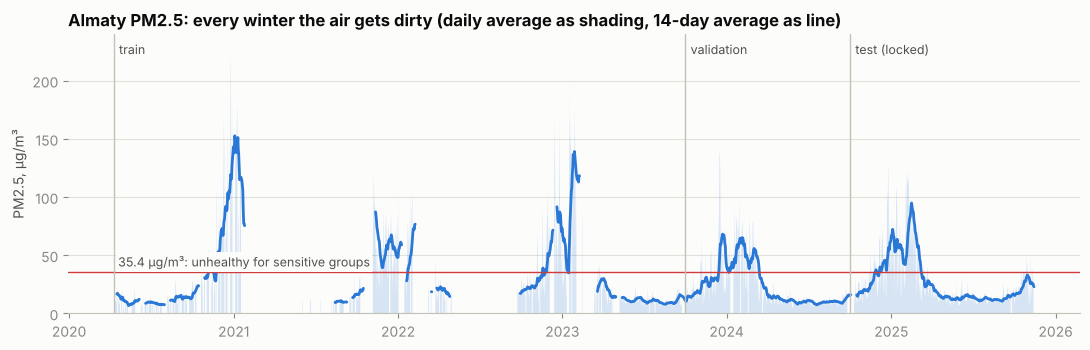

In [6]:
daily = daily_mean(pm_hourly)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.fill_between(daily.index, 0, daily.to_numpy(), color=BLUE, alpha=0.18, linewidth=0)
ax.plot(daily.rolling(14, min_periods=7).mean(), color=BLUE)
ax.axhline(ALERT_LEVEL, color=RED, linewidth=1)
ax.text(daily.index.min() + pd.Timedelta(days=10), ALERT_LEVEL + 5, "35.4 µg/m³: unhealthy for sensitive groups", color=INK2, fontsize=9,
        bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
top = float(np.nanmax(daily)) * 1.08
for start, label in [(daily.index.min(), "train"), (pd.Timestamp(SPLIT["val_start"]), "validation"),
                     (pd.Timestamp(SPLIT["test_start"]), "test (locked)")]:
    ax.axvline(start, color=AXIS, linewidth=1)
    ax.text(start + pd.Timedelta(days=12), top * 0.93, label, color=INK2, fontsize=9)
ax.set_ylim(0, top)
ax.set_ylabel("PM2.5, µg/m³")
ax.set_title("Almaty PM2.5: every winter the air gets dirty (daily average as shading, 14-day average as line)")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/01_pm25_history.png", dpi=160)
plt.show()

## 4. Simple baselines

* **Persistence** (required by the brief): "tomorrow will be like today". At 18:00 "today" means the last 24 hours.
* **Calendar-day persistence**: tomorrow = today's full calendar day. It knows 6 hours more than we do at 18:00,
  so it is a tougher comparison; we report it too.
* **Typical for the month**: the average of that calendar month in the training years.

In [7]:
def mae(y_true, y_pred):
    """Mean absolute error: on average, how many µg/m³ the forecast is off."""
    return float(np.mean(np.abs(np.asarray(y_true, float) - np.asarray(y_pred, float))))


def add_baselines(df, history):
    out = df.copy()
    out["persistence"] = out["pm_last24"]
    out["persistence_calendar"] = out["pm_today_full"].fillna(out["pm_last24"])
    monthly = history.groupby(history["target_date"].dt.month)["target"].mean()
    out["month_typical"] = out["target_date"].dt.month.map(monthly)
    return out


def score_table(df, columns):
    winter = heating_season(df["target_date"])
    return pd.DataFrame([{
        "forecast": name,
        "MAE Oct-Mar": mae(df.loc[winter, "target"], df.loc[winter, col]),
        "MAE all days": mae(df["target"], df[col]),
    } for name, col in columns.items()]).set_index("forecast")


BASELINES = {"Persistence (last 24 h at 18:00)": "persistence",
             "Persistence (full calendar day, knows 6 h more)": "persistence_calendar",
             "Typical value for the month": "month_typical"}
val = add_baselines(val, train)
print(f"Validation year, {int(heating_season(val['target_date']).sum())} Oct-Mar days / {len(val)} days in total")
score_table(val, BASELINES)

Validation year, 170 Oct-Mar days / 348 days in total


,MAE Oct-Mar,MAE all days
forecast,,
Persistence (last 24 h at 18:00),18.12,10.48
"Persistence (full calendar day, knows 6 h more)",16.57,9.60
Typical value for the month,26.26,14.36


## 5. Choose a model, using past winters only

We predict the logarithm of PM2.5 (smog values are very skewed) and turn it back to µg/m³ at the end.

Candidates:
* **Ridge regression**: a weighted sum of the inputs. Simple, and each weight can be explained.
* **Gradient boosting**: many small decision trees. More flexible, harder to explain.

Three sets of inputs, each adding something: **A** air history only → **B** + tomorrow's city weather →
**C** + the inversion signal (mountain temperature minus city temperature).

To make the choice less dependent on one winter, each candidate is checked on **two** past winters:
trained up to September 2022 and checked on 2022/23, then trained up to September 2023 and checked on 2023/24.
The test period is not used here.

**Rule written down before looking:** take the simplest candidate unless a more complex one is more than
5% better on the average of the two winters.

In [8]:
SKEWED = ["pm_last24", "pm_max24", "pm_last6", "pm_last72", "pm_prev24", "pm_night", "precip_tmrw", "snowfall_tmrw"]


def prepare(df, features):
    """Model inputs: the chosen columns, with very skewed ones put on a log scale."""
    X = df[features].copy()
    for col in [c for c in features if c in SKEWED]:
        X[col] = np.log1p(X[col])
    return X


def fit_ridge(df, features, alpha=10.0):
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    return model.fit(prepare(df, features), np.log1p(df["target"]))


def fit_boosting(df, features):
    model = HistGradientBoostingRegressor(max_leaf_nodes=4, learning_rate=0.03, max_iter=300, min_samples_leaf=15,
                                          l2_regularization=1.0, random_state=0)
    return model.fit(prepare(df, features), np.log1p(df["target"]))


def predict(model, df, features):
    return np.expm1(model.predict(prepare(df, features)))      # back from the log scale to µg/m³


past = data[data["target_date"] <= SPLIT["val_end"]]            # nothing from the test period
t = past["target_date"]
folds = {"winter 2022/23": (t <= "2022-09-30", (t >= "2022-10-01") & (t <= "2023-09-30")),
         "winter 2023/24": (t <= "2023-09-30", (t >= "2023-10-01") & (t <= "2024-09-30"))}
candidates = {
    "Persistence (last 24 h at 18:00)": None,
    "Ridge | A: air history only": (fit_ridge, FEATURES_A),
    "Ridge | B: + city weather tomorrow": (fit_ridge, FEATURES_B),
    "Ridge | C: + inversion signal": (fit_ridge, FEATURES_C),
    "Boosting | B: + city weather tomorrow": (fit_boosting, FEATURES_B),
    "Boosting | C: + inversion signal": (fit_boosting, FEATURES_C),
}
rows = []
for name, spec in candidates.items():
    row = {"candidate": name}
    for fold_name, (fit_mask, check_mask) in folds.items():
        fit_part, check_part = past[fit_mask], past[check_mask]
        winter = heating_season(check_part["target_date"])
        guess = check_part["pm_last24"] if spec is None else predict(spec[0](fit_part, spec[1]), check_part, spec[1])
        row[f"MAE {fold_name}"] = mae(check_part.loc[winter, "target"], np.asarray(guess)[winter.to_numpy()])
    row["average"] = np.mean([v for k, v in row.items() if k.startswith("MAE")])
    rows.append(row)
selection = pd.DataFrame(rows).set_index("candidate")
selection["vs persistence"] = (selection["average"] / selection.loc["Persistence (last 24 h at 18:00)", "average"] - 1).map("{:+.0%}".format)
selection

,MAE winter 2022/23,MAE winter 2023/24,average,vs persistence
candidate,,,,
Persistence (last 24 h at 18:00),24.16,18.12,21.14,+0%
Ridge | A: air history only,20.94,14.78,17.86,-16%
Ridge | B: + city weather tomorrow,14.72,12.66,13.69,-35%
Ridge | C: + inversion signal,14.25,14.54,14.40,-32%
Boosting | B: + city weather tomorrow,15.29,12.17,13.73,-35%
Boosting | C: + inversion signal,15.02,12.67,13.84,-35%


**What this shows (past winters only):**
* Knowing only the air history already helps a little; adding **tomorrow's weather** helps the most.
* The **inversion signal did not give a reliable extra gain**: it helped in one winter and hurt in the other.
  Temperature, sun and humidity in the city seem to carry most of that information already.
* **Boosting was not more than 5% better** than Ridge.

So, following the rule, the final model is **Ridge with input set B** (air history + tomorrow's city weather).
During development we also tried other Ridge strengths (1 to 100) and a second boosting library (LightGBM, 4 and 7
leaves, and a version predicting the change from today); none of them was clearly better on these two winters.

In [9]:
FEATURES = FEATURES_B

# ---- settings taken from the validation year (model trained on the training years only)
model_for_settings = fit_ridge(train, FEATURES)
val["model"] = predict(model_for_settings, val, FEATURES)


def alert_counts(y_true, y_pred, cutoff):
    """We warn when the forecast is >= cutoff. A day is really 'bad' when its PM2.5 is above ALERT_LEVEL."""
    bad, warn = np.asarray(y_true) > ALERT_LEVEL, np.asarray(y_pred) >= cutoff
    hits, misses = int((bad & warn).sum()), int((bad & ~warn).sum())
    false_alarms, quiet = int((~bad & warn).sum()), int((~bad & ~warn).sum())
    return {"bad days": hits + misses, "caught": hits, "missed": misses, "false alarms": false_alarms,
            "correctly quiet": quiet, "recall": hits / max(hits + misses, 1), "precision": hits / max(hits + false_alarms, 1)}


def best_cutoff(y_true, y_pred):
    """The warning cutoff with the lowest cost, where a miss costs MISS_COST and a false alarm costs 1."""
    grid = np.arange(15.0, 60.5, 0.5)
    cost = np.array([MISS_COST * alert_counts(y_true, y_pred, c)["missed"] + alert_counts(y_true, y_pred, c)["false alarms"]
                     for c in grid])
    ties = grid[cost == cost.min()]
    return float(ties[np.argmin(np.abs(ties - ALERT_LEVEL))])        # if several are equally good, stay close to 35.4


CUTOFF_MODEL = best_cutoff(val["target"], val["model"])
CUTOFF_PERSISTENCE = best_cutoff(val["target"], val["persistence"])

# likely range: how far off (on the log scale) was the model on validation days? keep the middle 80%.
# Errors are larger in the heating season, so the range is measured separately for Oct-Mar and Apr-Sep.
val_log_error = np.log1p(val["target"]) - np.log1p(val["model"])
val_winter = heating_season(val["target_date"])
RANGE = {"heating": [float(q) for q in np.quantile(val_log_error[val_winter], [0.10, 0.90])],
         "warm": [float(q) for q in np.quantile(val_log_error[~val_winter], [0.10, 0.90])]}


def likely_range(values, target_dates):
    """Low and high end of the likely range for each forecast."""
    season = heating_season(pd.Series(pd.to_datetime(target_dates))).to_numpy()
    low = np.where(season, RANGE["heating"][0], RANGE["warm"][0])
    high = np.where(season, RANGE["heating"][1], RANGE["warm"][1])
    log_value = np.log1p(np.asarray(values, float))
    return np.expm1(log_value + low), np.expm1(log_value + high)


print(f"warning cutoff for the model      : forecast >= {CUTOFF_MODEL} µg/m³")
print(f"warning cutoff for persistence    : last 24 h >= {CUTOFF_PERSISTENCE} µg/m³   (the baseline gets the same tuning)")
print(f"likely range around a forecast f  : Oct-Mar from f x {np.exp(RANGE['heating'][0]):.2f} to f x {np.exp(RANGE['heating'][1]):.2f}; "
      f"Apr-Sep from f x {np.exp(RANGE['warm'][0]):.2f} to f x {np.exp(RANGE['warm'][1]):.2f} (approximately)")
score_table(val, {**BASELINES, "Ridge, input set B (trained on train only)": "model"})

warning cutoff for the model      : forecast >= 32.5 µg/m³
warning cutoff for persistence    : last 24 h >= 29.5 µg/m³   (the baseline gets the same tuning)
likely range around a forecast f  : Oct-Mar from f x 0.53 to f x 1.39; Apr-Sep from f x 0.68 to f x 1.31 (approximately)


,MAE Oct-Mar,MAE all days
forecast,,
Persistence (last 24 h at 18:00),18.12,10.48
"Persistence (full calendar day, knows 6 h more)",16.57,9.60
Typical value for the month,26.26,14.36
"Ridge, input set B (trained on train only)",12.66,7.51


## 6. The final test — run once on the newest, locked data

The chosen model is trained again on everything before October 2024 and then evaluated on the test period
(October 2024 – November 2025). Nothing was tuned on these days.

In [10]:
train_and_val = data[masks["train"] | masks["validation"]]
final_model = fit_ridge(train_and_val, FEATURES)

test = add_baselines(test, train_and_val)
test["model"] = predict(final_model, test, FEATURES)
test["range_low"], test["range_high"] = likely_range(test["model"], test["target_date"])
winter_test = test[heating_season(test["target_date"])]

FORECASTS = {**BASELINES, "Our model (Ridge, air history + weather)": "model"}
test_scores = score_table(test, FORECASTS)
base = test_scores.loc["Persistence (last 24 h at 18:00)"]
test_scores["Oct-Mar vs persistence"] = (test_scores["MAE Oct-Mar"] / base["MAE Oct-Mar"] - 1).map("{:+.0%}".format)
print(f"Test period: {len(test)} days, of them {len(winter_test)} in Oct-Mar; "
      f"average PM2.5 in Oct-Mar: {winter_test['target'].mean():.1f} µg/m³")
test_scores

Test period: 396 days, of them 216 in Oct-Mar; average PM2.5 in Oct-Mar: 39.1 µg/m³


,MAE Oct-Mar,MAE all days,Oct-Mar vs persistence
forecast,,,
Persistence (last 24 h at 18:00),17.00,10.93,+0%
"Persistence (full calendar day, knows 6 h more)",15.31,9.91,-10%
Typical value for the month,18.52,11.68,+9%
"Our model (Ridge, air history + weather)",12.15,8.21,-29%


In [11]:
def weekly_bootstrap(diff, n_rounds=4000, block=7, seed=0):
    """95% interval for the average of `diff`, re-drawing whole weeks (days next to each other are similar)."""
    diff = np.asarray(diff, float)
    blocks = [diff[i:i + block] for i in range(0, len(diff), block)]
    rng = np.random.default_rng(seed)
    means = [np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), len(blocks))]).mean() for _ in range(n_rounds)]
    return np.percentile(means, [2.5, 97.5])


gain = np.abs(winter_test["target"] - winter_test["persistence"]) - np.abs(winter_test["target"] - winter_test["model"])
gain_tough = np.abs(winter_test["target"] - winter_test["persistence_calendar"]) - np.abs(winter_test["target"] - winter_test["model"])
ci, ci_tough = weekly_bootstrap(gain), weekly_bootstrap(gain_tough)
print(f"Oct-Mar, our model vs persistence at 18:00   : {gain.mean():.1f} µg/m³ smaller error per day (95% interval {ci[0]:.1f} to {ci[1]:.1f})")
print(f"Oct-Mar, our model vs calendar-day persistence: {gain_tough.mean():.1f} µg/m³ smaller error per day (95% interval {ci_tough[0]:.1f} to {ci_tough[1]:.1f})")
inside = (winter_test["target"] >= winter_test["range_low"]) & (winter_test["target"] <= winter_test["range_high"])
print(f"Likely range (built to hold 80% of days): held {inside.mean():.0%} of Oct-Mar test days "
      f"and {((test['target'] >= test['range_low']) & (test['target'] <= test['range_high'])).mean():.0%} of all test days")

Oct-Mar, our model vs persistence at 18:00   : 4.8 µg/m³ smaller error per day (95% interval 3.0 to 7.0)
Oct-Mar, our model vs calendar-day persistence: 3.2 µg/m³ smaller error per day (95% interval 1.4 to 5.2)
Likely range (built to hold 80% of days): held 76% of Oct-Mar test days and 74% of all test days


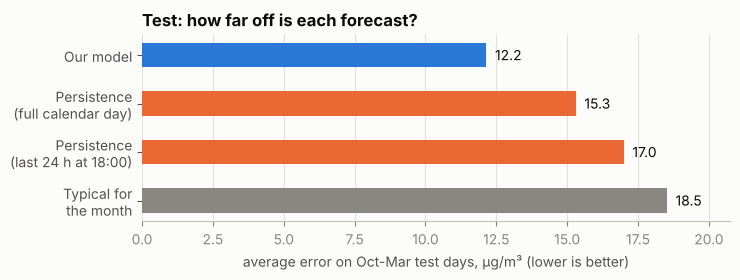

In [12]:
labels = ["Our model", "Persistence\n(full calendar day)", "Persistence\n(last 24 h at 18:00)", "Typical for\nthe month"]
values = [test_scores.loc[k, "MAE Oct-Mar"] for k in ["Our model (Ridge, air history + weather)",
          "Persistence (full calendar day, knows 6 h more)", "Persistence (last 24 h at 18:00)", "Typical value for the month"]]
fig, ax = plt.subplots(figsize=(7.5, 2.9))
bars = ax.barh(labels[::-1], values[::-1], height=0.5, color=[MUTED, ORANGE, ORANGE, BLUE])
for bar, value in zip(bars, values[::-1]):
    ax.text(value + 0.3, bar.get_y() + bar.get_height() / 2, f"{value:.1f}", va="center", color=INK, fontsize=10)
ax.set_xlim(0, max(values) * 1.12)
ax.set_xlabel("average error on Oct-Mar test days, µg/m³ (lower is better)")
ax.set_title("Test: how far off is each forecast?")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", colors=INK2)
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/02_test_error.png", dpi=160)
plt.show()

### The decision: warn or not?
A warning means "plan the PE lesson indoors". We count separately the bad days that were **missed**
and the **false alarms** (a warning on a day that turned out fine).

In [13]:
alerts = pd.DataFrame({
    "Our model": alert_counts(winter_test["target"], winter_test["model"], CUTOFF_MODEL),
    "Persistence (last 24 h at 18:00)": alert_counts(winter_test["target"], winter_test["persistence"], CUTOFF_PERSISTENCE),
    "Persistence, simple rule (warn if last 24 h > 35.4)": alert_counts(winter_test["target"], winter_test["persistence"], ALERT_LEVEL + 1e-9),
}).T
count_columns = ["bad days", "caught", "missed", "false alarms", "correctly quiet"]
alerts[count_columns] = alerts[count_columns].astype(int)
alerts[["recall", "precision"]] = alerts[["recall", "precision"]].astype(float).round(2)
print(f"Oct-Mar test days: {len(winter_test)}")
alerts

Oct-Mar test days: 216


,bad days,caught,missed,false alarms,correctly quiet,recall,precision
Our model,88,72,16,22,106,0.82,0.77
Persistence (last 24 h at 18:00),88,69,19,40,88,0.78,0.63
"Persistence, simple rule (warn if last 24 h > 35.4)",88,57,31,28,100,0.65,0.67


### The hardest days: when the air changes
"Tomorrow will be like today" must be wrong exactly when it matters most: on the **first day** of a smog
episode and on the **first clean day** after one. Here the days are grouped by what happened.

In [14]:
def kind_of_day(row):
    dirty_now, dirty_next = row["pm_last24"] > ALERT_LEVEL, row["target"] > ALERT_LEVEL
    if dirty_next and not dirty_now:
        return "1. smog starts (clean -> bad)"
    if dirty_next and dirty_now:
        return "2. smog continues (bad -> bad)"
    if not dirty_next and dirty_now:
        return "3. air clears (bad -> clean)"
    return "4. stays clean (clean -> clean)"


winter_test = winter_test.assign(kind=winter_test.apply(kind_of_day, axis=1),
                                 warn_model=winter_test["model"] >= CUTOFF_MODEL,
                                 warn_persistence=winter_test["persistence"] >= CUTOFF_PERSISTENCE)
by_kind = winter_test.groupby("kind").agg(
    days=("target", "size"),
    model_warned=("warn_model", "sum"),
    persistence_warned=("warn_persistence", "sum"),
    model_error=("model", lambda s: mae(winter_test.loc[s.index, "target"], s)),
    persistence_error=("persistence", lambda s: mae(winter_test.loc[s.index, "target"], s)),
)
by_kind

,days,model_warned,persistence_warned,model_error,persistence_error
kind,,,,,
1. smog starts (clean -> bad),31,17,12,15.41,25.12
2. smog continues (bad -> bad),57,55,57,19.99,21.23
3. air clears (bad -> clean),28,13,28,13.11,33.13
4. stays clean (clean -> clean),100,9,12,6.41,7.56


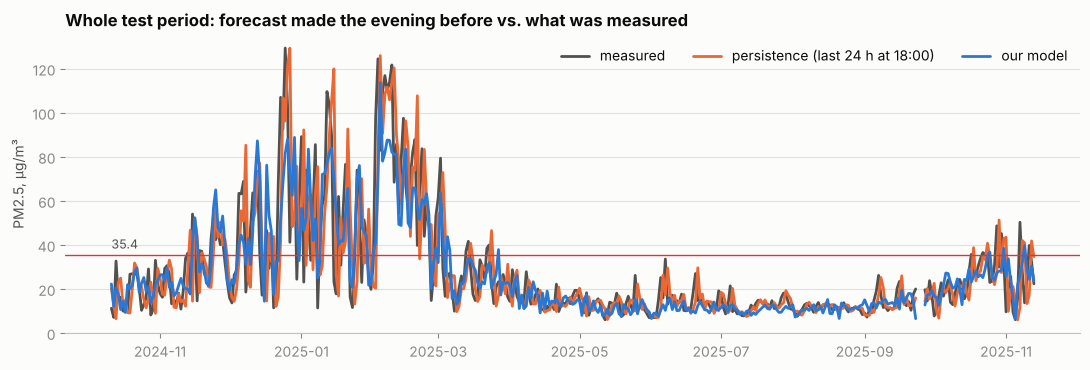

In [15]:
by_day = test.set_index("target_date")[["target", "persistence", "model"]]
by_day = by_day.reindex(pd.date_range(by_day.index.min(), by_day.index.max(), freq="D"))    # missing days break the lines
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(by_day["target"], color=INK2, label="measured")
ax.plot(by_day["persistence"], color=ORANGE, label="persistence (last 24 h at 18:00)")
ax.plot(by_day["model"], color=BLUE, label="our model")
ax.axhline(ALERT_LEVEL, color=RED, linewidth=1)
ax.text(by_day.index.min(), ALERT_LEVEL + 3, "35.4", color=INK2, fontsize=9)
ax.set_ylabel("PM2.5, µg/m³")
ax.set_title("Whole test period: forecast made the evening before vs. what was measured")
ax.legend(loc="upper right", ncol=3)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/03_test_period.png", dpi=160)
plt.show()

## 7. Does it still work with a real weather forecast?

So far "tomorrow's weather" came from the weather model's own record of what happened, as if the forecast were
perfect. For the test period we also downloaded **real archived forecasts of the same weather model**
(Open-Meteo Previous Runs API): for every hour, what the forecast said one day earlier and two days earlier.
Our model is **not** retrained; only its weather inputs for tomorrow are replaced.

* *1 day old* is close to what a user really has at 18:00 (for the last 6 hours of tomorrow it is slightly newer).
* *2 days old* is older than what a user really has, so it is a stricter test than reality.

In [16]:
forecast_hourly = load_weather_hourly("data/raw/forecast_archive_city.csv")


def weather_from_forecast(suffix, hourly=None):
    """Daily city weather built from one version of the archived forecast ('' = newest run)."""
    hourly = forecast_hourly if hourly is None else hourly
    names = ["temperature_2m", "relative_humidity_2m", "surface_pressure", "precipitation", "snowfall",
             "cloud_cover", "shortwave_radiation", "wind_speed_10m", "wind_direction_10m", "wind_gusts_10m"]
    return city_daily(hourly[[n + suffix for n in names]].set_axis(names, axis=1))


# the newest run in this archive is the same data as our weather record (checked: identical daily values)
newest = weather_from_forecast("")
same_days = newest.index.intersection(weather_daily.index)
assert np.allclose(newest.loc[same_days, CITY_COLS], weather_daily.loc[same_days, CITY_COLS], atol=1e-6)

weather_columns = [f"{c}_tmrw" for c in CITY_COLS] + [f"{c}_change" for c in CHANGE_COLS]
rows = []
for label, suffix in [("a real forecast, 1 day old", "_previous_day1"), ("a real forecast, 2 days old", "_previous_day2")]:
    version = add_weather(test.drop(columns=weather_columns), weather_daily[CITY_COLS], weather_from_forecast(suffix))
    version = version.dropna(subset=FEATURES)
    version["model"] = predict(final_model, version, FEATURES)
    winter = version[heating_season(version["target_date"])]
    counts = alert_counts(winter["target"], winter["model"], CUTOFF_MODEL)
    rows.append({"weather for tomorrow taken from": label, "Oct-Mar days": len(winter),
                 "MAE Oct-Mar": mae(winter["target"], winter["model"]), "MAE all days": mae(version["target"], version["model"]),
                 "missed": counts["missed"], "false alarms": counts["false alarms"]})
reference = alert_counts(winter_test["target"], winter_test["model"], CUTOFF_MODEL)
rows.insert(0, {"weather for tomorrow taken from": "the weather record (as if the forecast were perfect)",
                "Oct-Mar days": len(winter_test), "MAE Oct-Mar": mae(winter_test["target"], winter_test["model"]),
                "MAE all days": mae(test["target"], test["model"]), "missed": reference["missed"], "false alarms": reference["false alarms"]})
rows.append({"weather for tomorrow taken from": "(baseline) persistence, needs no weather", "Oct-Mar days": len(winter_test),
             "MAE Oct-Mar": mae(winter_test["target"], winter_test["persistence"]), "MAE all days": mae(test["target"], test["persistence"]),
             "missed": alerts.loc["Persistence (last 24 h at 18:00)", "missed"], "false alarms": alerts.loc["Persistence (last 24 h at 18:00)", "false alarms"]})
real_forecast_table = pd.DataFrame(rows).set_index("weather for tomorrow taken from")
real_forecast_table

,Oct-Mar days,MAE Oct-Mar,MAE all days,missed,false alarms
weather for tomorrow taken from,,,,,
the weather record (as if the forecast were perfect),216,12.15,8.21,16,22
"a real forecast, 1 day old",216,12.15,8.27,18,22
"a real forecast, 2 days old",216,12.06,8.20,16,21
"(baseline) persistence, needs no weather",216,17.00,10.93,19,40


## 8. From a warning to an action: the timetable that breathes

A warning still leaves the work to the teacher. So we let the forecast **act**.

**The situation.** The gym cannot hold every class, so each school week (Mon-Fri) a class must have exactly
**2 PE lessons outdoors**. Which two days? A fixed timetable decides this in September and never looks at the air.

**The rule (no tuned numbers).** Every evening at 18:00 we look at the forecast for tomorrow and say
"outdoors tomorrow" only if tomorrow is expected to be among the cleanest days we can still hope for:
with *k* outdoor lessons still owed and *n* school days left, tomorrow must be cleaner than the cleanest *k/n*
share of the last 14 days. When the days left equal the lessons owed, there is no choice.

**How it is scored.** Not by forecast error, but by what the children breathe: the average PM2.5 on the days the
outdoor lessons really happened. We compare four planners:
a fixed timetable (the average of all possible fixed pairs of days), the same rule fed with "tomorrow = last 24 h",
the rule fed with our forecast, and a planner with perfect hindsight (the two cleanest days of each week).
The rule was written and tried on the validation year first; then it was run once on the test period.

In [17]:
QUOTA = 2           # outdoor lessons that must happen in each school week
LOOKBACK = 14       # days of recent measurements used as the yardstick


def play_timetable(rows, estimate_col, quota=QUOTA, history=None):
    """Replay the rule over every complete Oct-Mar school week in `rows`.
    Returns one line per week (what was breathed) and the day-by-day decisions.
    `history` = daily measurements used as the yardstick (default: the reference monitor)."""
    history = daily if history is None else history
    by_day = rows.set_index("target_date")
    weeks, log = [], []
    for monday in pd.date_range(by_day.index.min().normalize(), by_day.index.max(), freq="W-MON"):
        days = [monday + pd.Timedelta(days=i) for i in range(5)]
        if not all(d in by_day.index for d in days) or not heating_season(pd.Series(days)).all():
            continue                                    # we need all five school days, inputs and answers
        owed, chosen = quota, []
        for i, day in enumerate(days):
            left = 5 - i                                # school days left, counting this one
            evening = day - pd.Timedelta(days=1)        # the decision is made at 18:00 the day before
            recent = history[evening - pd.Timedelta(days=LOOKBACK): evening - pd.Timedelta(days=1)].dropna()
            estimate = by_day.loc[day, estimate_col]
            if owed == 0:
                go, why = False, "the outdoor lessons of this week are done"
            elif owed >= left:
                go, why = True, "no days left to wait"
            else:
                bar = np.quantile(recent, owed / left) if len(recent) >= 5 else np.inf
                go = estimate <= bar
                why = f"forecast {estimate:.0f} vs bar {bar:.0f} (cleanest {owed}/{left} of the last {LOOKBACK} days)"
            if go:
                chosen.append(day)
                owed -= 1
            log.append({"week": monday, "day": day, "forecast": estimate, "decision": "OUTDOORS" if go else "gym",
                        "why": why, "measured": by_day.loc[day, "target"]})
        measured = by_day.loc[days, "target"]
        weeks.append({"week": monday, "rule": measured.loc[chosen].mean(), "fixed timetable": measured.mean(),
                      "perfect hindsight": measured.nsmallest(quota).mean()})
    return pd.DataFrame(weeks).set_index("week"), pd.DataFrame(log)


def timetable_summary(rows, quotas=(1, 2, 3), history=None):
    out = []
    for quota in quotas:
        with_model, _ = play_timetable(rows, "model", quota, history)
        with_persistence, _ = play_timetable(rows, "persistence", quota, history)
        fixed, best = with_model["fixed timetable"].mean(), with_model["perfect hindsight"].mean()
        out.append({"outdoor lessons per week": quota, "weeks": len(with_model), "fixed timetable": fixed,
                    "rule + persistence": with_persistence["rule"].mean(), "rule + our forecast": with_model["rule"].mean(),
                    "perfect hindsight": best,
                    "avoidable dirt removed (persistence)": f"{(fixed - with_persistence['rule'].mean()) / (fixed - best):.0%}",
                    "avoidable dirt removed (our forecast)": f"{(fixed - with_model['rule'].mean()) / (fixed - best):.0%}"})
    return pd.DataFrame(out).set_index("outdoor lessons per week")


print("Validation year (rule written and tried here first) — average PM2.5 on outdoor-lesson days, µg/m³")
timetable_validation = timetable_summary(val)
timetable_validation

Validation year (rule written and tried here first) — average PM2.5 on outdoor-lesson days, µg/m³


,weeks,fixed timetable,rule + persistence,rule + our forecast,perfect hindsight,avoidable dirt removed (persistence),avoidable dirt removed (our forecast)
outdoor lessons per week,,,,,,,
1,22,35.17,37.60,29.33,17.17,-14%,32%
2,22,35.17,33.69,32.54,22.11,11%,20%
3,22,35.17,34.74,33.34,25.58,4%,19%


In [18]:
print("TEST period (run once) — average PM2.5 on outdoor-lesson days, µg/m³")
timetable_test = timetable_summary(test)
timetable_test

TEST period (run once) — average PM2.5 on outdoor-lesson days, µg/m³


,weeks,fixed timetable,rule + persistence,rule + our forecast,perfect hindsight,avoidable dirt removed (persistence),avoidable dirt removed (our forecast)
outdoor lessons per week,,,,,,,
1,29,39.98,34.11,32.57,22.33,33%,42%
2,29,39.98,37.50,35.40,26.71,19%,35%
3,29,39.98,38.83,37.70,31.12,13%,26%


In [19]:
weeks_model, decisions = play_timetable(test, "model")
weeks_persistence, _ = play_timetable(test, "persistence")
rng = np.random.default_rng(0)
saved = (weeks_model["fixed timetable"] - weeks_model["rule"]).to_numpy()
saved_vs_persistence = (weeks_persistence["rule"] - weeks_model["rule"]).to_numpy()
draws = rng.integers(0, len(saved), (4000, len(saved)))
ci_fixed, ci_pers = np.percentile(saved[draws].mean(axis=1), [2.5, 97.5]), np.percentile(saved_vs_persistence[draws].mean(axis=1), [2.5, 97.5])
print(f"{len(saved)} complete Oct-Mar school weeks in the test period, {QUOTA} outdoor lessons per week.")
print(f"Our planner vs a fixed timetable     : {saved.mean():.1f} µg/m³ cleaner air per outdoor lesson (95% interval {ci_fixed[0]:.1f} to {ci_fixed[1]:.1f})")
print(f"Our planner vs the persistence planner: {saved_vs_persistence.mean():.1f} µg/m³ cleaner (95% interval {ci_pers[0]:.1f} to {ci_pers[1]:.1f})")
print(f"Weeks in which our planner beat / tied / lost to the fixed timetable: "
      f"{int((saved > 0.05).sum())} / {int((np.abs(saved) <= 0.05).sum())} / {int((saved < -0.05).sum())}")

# one week, replayed evening by evening: the test week with the dirtiest air (chosen by that rule, not by the result)
dirtiest = weeks_model["fixed timetable"].idxmax()
print(f"\nThe dirtiest complete school week of the test period (starts {dirtiest:%d %b %Y}):")
replay = decisions[decisions["week"] == dirtiest][["day", "forecast", "decision", "why", "measured"]].copy()
replay["day"] = replay["day"].dt.strftime("%a %d %b")
replay.set_index("day").round(0)

29 complete Oct-Mar school weeks in the test period, 2 outdoor lessons per week.
Our planner vs a fixed timetable     : 4.6 µg/m³ cleaner air per outdoor lesson (95% interval 0.8 to 8.8)
Our planner vs the persistence planner: 2.1 µg/m³ cleaner (95% interval -1.3 to 5.9)
Weeks in which our planner beat / tied / lost to the fixed timetable: 17 / 0 / 12

The dirtiest complete school week of the test period (starts 03 Feb 2025):


,forecast,decision,why,measured
day,,,,
Mon 03 Feb,69.0,gym,forecast 69 vs bar 32 (cleanest 2/5 of the las...,125.0
Tue 04 Feb,114.0,gym,forecast 114 vs bar 40 (cleanest 2/4 of the la...,83.0
Wed 05 Feb,78.0,gym,forecast 78 vs bar 53 (cleanest 2/3 of the las...,110.0
Thu 06 Feb,82.0,OUTDOORS,no days left to wait,117.0
Fri 07 Feb,88.0,OUTDOORS,no days left to wait,110.0


## 9. Two checks added later (the forecasting model was not changed)
These checks were written after the forecast test in section 6 had been run. They look at the same test days
from a new angle. The model, its inputs and its warning cutoff stay exactly as they were, and we decided
beforehand to report both checks whatever they showed.

### 9a. Is a free global air-quality forecast enough?
The Copernicus **CAMS** global model publishes PM2.5 for every place on Earth; anyone can read it through the
Open-Meteo Air Quality API. These values are model estimates, not measurements. If CAMS were good enough for
Almaty, a school would not need a local model at all.

CAMS gets the same treatment as persistence: its warning cutoff is tuned on the validation year with the same
cost rule. One thing favours CAMS here: the archive keeps its freshest runs, which are a little better than a
true day-ahead forecast.

In [20]:
def load_cams_daily(path="data/raw/cams_openmeteo_almaty_pm25_hourly.csv"):
    """Daily average of the CAMS global model's PM2.5 for the monitor's grid cell (Almaty calendar days)."""
    raw = pd.read_csv(path)
    s = pd.Series(raw["cams_pm25"].to_numpy(), index=utc_to_almaty(raw["datetime_utc"]))
    return daily_mean(s.groupby(level=0).mean().asfreq("h"))


cams_daily = load_cams_daily()
val["cams"] = cams_daily.reindex(val["target_date"]).to_numpy()              # the CAMS value for the answer day D+1
test["cams"] = cams_daily.reindex(test["target_date"]).to_numpy()
winter_cams = winter_test.assign(cams=cams_daily.reindex(winter_test["target_date"]).to_numpy())
assert val["cams"].notna().all() and test["cams"].notna().all()
CUTOFF_CAMS = best_cutoff(val["target"], val["cams"])                         # validation year only, same rule as the others

cams_rows = []
for name, col, cutoff in [("Our model", "model", CUTOFF_MODEL),
                          ("Persistence (last 24 h at 18:00)", "persistence", CUTOFF_PERSISTENCE),
                          ("Global model CAMS, cutoff tuned like the others", "cams", CUTOFF_CAMS),
                          ("Global model CAMS, plain rule (warn above 35.4)", "cams", ALERT_LEVEL + 1e-9)]:
    counts = alert_counts(winter_cams["target"], winter_cams[col], cutoff)
    cams_rows.append({"forecast": name, "MAE Oct-Mar": mae(winter_cams["target"], winter_cams[col]),
                      "MAE all days": mae(test["target"], test[col]),
                      "average bias Oct-Mar": float((winter_cams[col] - winter_cams["target"]).mean()),
                      "warning cutoff": round(cutoff, 1), "caught": counts["caught"], "missed": counts["missed"],
                      "false alarms": counts["false alarms"]})
cams_table = pd.DataFrame(cams_rows).set_index("forecast")
cams_gain = np.abs(winter_cams["target"] - winter_cams["cams"]) - np.abs(winter_cams["target"] - winter_cams["model"])
cams_ci = weekly_bootstrap(cams_gain)
print(f"Oct-Mar test days: {len(winter_cams)}, of them {int((winter_cams['target'] > ALERT_LEVEL).sum())} bad. "
      f"A negative bias means the forecast is too low on average.")
print(f"Our model vs CAMS: {cams_gain.mean():.1f} µg/m³ smaller error per day (95% interval {cams_ci[0]:.1f} to {cams_ci[1]:.1f})")
cams_table

Oct-Mar test days: 216, of them 88 bad. A negative bias means the forecast is too low on average.
Our model vs CAMS: 4.4 µg/m³ smaller error per day (95% interval 1.7 to 7.6)


,MAE Oct-Mar,MAE all days,average bias Oct-Mar,warning cutoff,caught,missed,false alarms
forecast,,,,,,,
Our model,12.15,8.21,-1.16e+00,32.5,72,16,22
Persistence (last 24 h at 18:00),17.00,10.93,-6.39e-03,29.5,69,19,40
"Global model CAMS, cutoff tuned like the others",16.59,11.03,-1.07e+01,22.5,87,1,66
"Global model CAMS, plain rule (warn above 35.4)",16.59,11.03,-1.07e+01,35.4,37,51,10


### 9b. Does the advice still hold if we only count school hours?
The model forecasts the average of the whole day, but a PE lesson happens between 08:00 and 18:00, and in
winter the nights are often dirtier than the days. So the same warnings are scored once more against the air
**during school hours only** (a day counts if at least 6 of its 10 daytime hours were measured).

In [21]:
def school_hours_mean(pm):
    """Average PM2.5 between 08:00 and 18:00 of each calendar day; needs at least 6 of the 10 hourly values."""
    part = pm[(pm.index.hour >= 8) & (pm.index.hour < 18)]
    g = part.groupby(part.index.normalize())
    return g.mean().where(g.count() >= 6)


def school_week_scores(log, school_air, quota=QUOTA):
    """The timetable scored by school-hours air: lesson days of the rule, a fixed timetable, perfect hindsight."""
    log = log.assign(school=school_air.reindex(log["day"]).to_numpy())
    by_week = log.groupby("week")["school"]
    chosen = log[log["decision"] == "OUTDOORS"].groupby("week")["school"].mean()
    return {"rule": float(chosen.mean()), "fixed timetable": float(by_week.mean().mean()),
            "perfect hindsight": float(by_week.apply(lambda s: s.nsmallest(quota).mean()).mean())}


school = school_hours_mean(pm_hourly)
winter_school = winter_test.assign(school=school.reindex(winter_test["target_date"]).to_numpy()).dropna(subset=["school"])
school_alerts = pd.DataFrame({
    "Our model": alert_counts(winter_school["school"], winter_school["model"], CUTOFF_MODEL),
    "Persistence (last 24 h at 18:00)": alert_counts(winter_school["school"], winter_school["persistence"], CUTOFF_PERSISTENCE),
}).T
school_alerts[count_columns] = school_alerts[count_columns].astype(int)
school_alerts[["recall", "precision"]] = school_alerts[["recall", "precision"]].astype(float).round(2)
_, decisions_persistence = play_timetable(test, "persistence")
school_timetable = {"rule + our forecast": school_week_scores(decisions, school),
                    "rule + persistence": school_week_scores(decisions_persistence, school)}
print(f"Oct-Mar test days with a school-hours value: {len(winter_school)}. Average PM2.5: whole day "
      f"{winter_school['target'].mean():.1f}, school hours {winter_school['school'].mean():.1f} µg/m³.")
print(f"Bad days by the whole-day average: {int((winter_school['target'] > ALERT_LEVEL).sum())}; "
      f"by the school-hours average: {int((winter_school['school'] > ALERT_LEVEL).sum())}.")
print(f"Timetable, school-hours PM2.5 on outdoor-lesson days: fixed timetable {school_timetable['rule + our forecast']['fixed timetable']:.1f}, "
      f"rule + persistence {school_timetable['rule + persistence']['rule']:.1f}, "
      f"rule + our forecast {school_timetable['rule + our forecast']['rule']:.1f}, "
      f"perfect hindsight {school_timetable['rule + our forecast']['perfect hindsight']:.1f} µg/m³")
school_alerts

Oct-Mar test days with a school-hours value: 216. Average PM2.5: whole day 39.1, school hours 51.8 µg/m³.
Bad days by the whole-day average: 88; by the school-hours average: 115.
Timetable, school-hours PM2.5 on outdoor-lesson days: fixed timetable 54.0, rule + persistence 50.8, rule + our forecast 48.4, perfect hindsight 31.8 µg/m³


,bad days,caught,missed,false alarms,correctly quiet,recall,precision
Our model,115,81,34,13,88,0.70,0.86
Persistence (last 24 h at 18:00),115,83,32,26,75,0.72,0.76


## 10. A year the model never saw: 2026, on a different sensor
The reference monitor's public record stops in November 2025. To check the frozen model on truly new days we
took a **citizen-science sensor** (sensor.community SDS011 no. 78340, central Almaty, about 2 km from the
reference monitor), 15 January – 14 November 2026.

The rules of this check were committed to git **before any number was computed**
(`docs/process_ru/PROJECT_SPEC.md`, amendment 7, commit `dd8b550`):

* The model from section 6, its warning cutoff and its likely range are frozen. Nothing is retrained and the
  sensor is not rescaled.
* Tomorrow's weather is a **real archived forecast that was 2 days old**, so it certainly existed at 18:00.
  The 1-day-old forecast is shown as well.
* The baseline is persistence on the same sensor. The main score is the Oct–Mar error against it.
* A low-cost optical sensor over-reads in humid air and stands at a different place, so "35.4" on its scale is
  not the same level as on the reference monitor. The warning counts are therefore secondary.

In [22]:
citizen_hourly = load_pm_hourly("data/raw/citizen_sds011_78340_hourly.csv")
citizen_daily = daily_mean(citizen_hourly)
forecast_2026 = load_weather_hourly("data/raw/forecast_archive_city_2026.csv")
record_2026 = weather_from_forecast("", forecast_2026)        # what the weather model recorded for each day of 2026
EXTERNAL_LAST_DAY = "2026-11-14"                                # the last complete day in the sensor archive when this was run

external_base = build_dataset(citizen_hourly, record_2026)
external_base = external_base[external_base["target_date"] <= EXTERNAL_LAST_DAY]


def external_rows(suffix):
    """Evenings of 2026: the citizen sensor's readings up to 18:00 + an archived weather forecast for tomorrow."""
    rows = add_weather(external_base.drop(columns=weather_columns), record_2026, weather_from_forecast(suffix, forecast_2026))
    rows = rows.dropna(subset=FEATURES)
    rows["persistence"] = rows["pm_last24"]
    rows["model"] = predict(final_model, rows, FEATURES)       # the frozen model from section 6
    rows["range_low"], rows["range_high"] = likely_range(rows["model"], rows["target_date"])
    rows["cams"] = cams_daily.reindex(rows["target_date"]).to_numpy()
    return rows


def external_line(rows, label, col, cutoff):
    winter = rows[heating_season(rows["target_date"])]
    counts = alert_counts(winter["target"], winter[col], cutoff)
    return {"forecast": label, "MAE Oct-Mar": mae(winter["target"], winter[col]), "MAE all days": mae(rows["target"], rows[col]),
            "caught": counts["caught"], "missed": counts["missed"], "false alarms": counts["false alarms"]}


external = external_rows("_previous_day2")                      # main version
external_day1 = external_rows("_previous_day1")
ext_winter = external[heating_season(external["target_date"])]
ext_table = pd.DataFrame([
    external_line(external, "Persistence (last 24 h at 18:00), same sensor", "persistence", CUTOFF_PERSISTENCE),
    external_line(external, "Global model CAMS", "cams", CUTOFF_CAMS),
    external_line(external, "Our frozen model + a real forecast, 2 days old (main)", "model", CUTOFF_MODEL),
    external_line(external_day1, "Our frozen model + a real forecast, 1 day old", "model", CUTOFF_MODEL),
]).set_index("forecast")
ext_gain = np.abs(ext_winter["target"] - ext_winter["persistence"]) - np.abs(ext_winter["target"] - ext_winter["model"])
ext_ci = weekly_bootstrap(ext_gain)
ext_gain_all = np.abs(external["target"] - external["persistence"]) - np.abs(external["target"] - external["model"])
ext_ci_all = weekly_bootstrap(ext_gain_all)
ext_inside = (ext_winter["target"] >= ext_winter["range_low"]) & (ext_winter["target"] <= ext_winter["range_high"])
print(f"Citizen sensor: {int(citizen_hourly.notna().sum()):,} valid hours, {citizen_hourly.index.min():%d %b %Y} .. {citizen_hourly.index.max():%d %b %Y}")
print(f"Evenings with inputs and an answer: {len(external)} ({external['target_date'].min():%d %b %Y} .. {external['target_date'].max():%d %b %Y}), "
      f"of them {len(ext_winter)} in Oct-Mar; {int((ext_winter['target'] > ALERT_LEVEL).sum())} of those were above 35.4 on this sensor")
print(f"Oct-Mar, frozen model vs persistence: {ext_gain.mean():.1f} µg/m³ smaller error per day (95% interval {ext_ci[0]:.1f} to {ext_ci[1]:.1f})")
print(f"All days, frozen model vs persistence: {ext_gain_all.mean():.1f} µg/m³ smaller error per day (95% interval {ext_ci_all[0]:.1f} to {ext_ci_all[1]:.1f})")
print(f"Likely range (built to hold 80% of days): held {ext_inside.mean():.0%} of the Oct-Mar days")
late = ext_winter[ext_winter["target_date"] >= "2026-01-15"]      # the protocol note guessed the archive started on 15 January
print(f"(Oct-Mar days from 15 January only: {len(late)} days, model {mae(late['target'], late['model']):.1f}, "
      f"persistence {mae(late['target'], late['persistence']):.1f})")
ext_table

Citizen sensor: 5,844 valid hours, 01 Jan 2026 .. 15 Nov 2026
Evenings with inputs and an answer: 234 (03 Jan 2026 .. 14 Nov 2026), of them 115 in Oct-Mar; 10 of those were above 35.4 on this sensor
Oct-Mar, frozen model vs persistence: -2.4 µg/m³ smaller error per day (95% interval -3.4 to -1.3)
All days, frozen model vs persistence: -1.6 µg/m³ smaller error per day (95% interval -2.2 to -0.9)
Likely range (built to hold 80% of days): held 71% of the Oct-Mar days
(Oct-Mar days from 15 January only: 103 days, model 9.7, persistence 7.1)


/tmp/ipykernel_1505/1351844555.py:95: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  day_of_year = df["target_date"].dt.dayofyear
/tmp/ipykernel_1505/1351844555.py:98: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["weekend_tmrw"] = (df["target_date"].dt.dayofweek >= 5).astype(int)


,MAE Oct-Mar,MAE all days,caught,missed,false alarms
forecast,,,,,
"Persistence (last 24 h at 18:00), same sensor",7.48,4.51,5,5,9
Global model CAMS,12.43,12.18,10,0,76
"Our frozen model + a real forecast, 2 days old (main)",9.89,6.07,8,2,15
"Our frozen model + a real forecast, 1 day old",9.89,6.13,7,3,15


In [23]:
ext_winter = ext_winter.assign(kind=ext_winter.apply(kind_of_day, axis=1),
                               warn_model=ext_winter["model"] >= CUTOFF_MODEL,
                               warn_persistence=ext_winter["persistence"] >= CUTOFF_PERSISTENCE)
ext_by_kind = ext_winter.groupby("kind").agg(
    days=("target", "size"),
    model_warned=("warn_model", "sum"),
    persistence_warned=("warn_persistence", "sum"),
    model_error=("model", lambda s: mae(ext_winter.loc[s.index, "target"], s)),
    persistence_error=("persistence", lambda s: mae(ext_winter.loc[s.index, "target"], s)),
)
ext_by_kind

,days,model_warned,persistence_warned,model_error,persistence_error
kind,,,,,
1. smog starts (clean -> bad),6,4,1,14.18,20.39
2. smog continues (bad -> bad),4,4,4,17.79,7.17
3. air clears (bad -> clean),5,5,5,23.80,20.76
4. stays clean (clean -> clean),100,10,4,8.62,6.06


In [24]:
print("2026, citizen sensor — the timetable rule (average PM2.5 on outdoor-lesson days, µg/m³)")
ext_timetable = timetable_summary(external, history=citizen_daily)
ext_weeks_model, _ = play_timetable(external, "model", history=citizen_daily)
ext_weeks_persistence, _ = play_timetable(external, "persistence", history=citizen_daily)
ext_saved = (ext_weeks_model["fixed timetable"] - ext_weeks_model["rule"]).to_numpy()
ext_saved_vs_persistence = (ext_weeks_persistence["rule"] - ext_weeks_model["rule"]).to_numpy()
ext_draws = np.random.default_rng(0).integers(0, len(ext_saved), (4000, len(ext_saved)))
ext_ci_fixed = np.percentile(ext_saved[ext_draws].mean(axis=1), [2.5, 97.5])
ext_ci_pers = np.percentile(ext_saved_vs_persistence[ext_draws].mean(axis=1), [2.5, 97.5])
print(f"{len(ext_saved)} complete Oct-Mar school weeks, {QUOTA} outdoor lessons per week.")
print(f"Our planner vs a fixed timetable      : {ext_saved.mean():.1f} µg/m³ cleaner (95% interval {ext_ci_fixed[0]:.1f} to {ext_ci_fixed[1]:.1f})")
print(f"Our planner vs the persistence planner: {ext_saved_vs_persistence.mean():.1f} µg/m³ cleaner (95% interval {ext_ci_pers[0]:.1f} to {ext_ci_pers[1]:.1f})")
ext_timetable

2026, citizen sensor — the timetable rule (average PM2.5 on outdoor-lesson days, µg/m³)


15 complete Oct-Mar school weeks, 2 outdoor lessons per week.
Our planner vs a fixed timetable      : 2.6 µg/m³ cleaner (95% interval 0.2 to 5.2)
Our planner vs the persistence planner: 2.2 µg/m³ cleaner (95% interval -0.0 to 5.6)


,weeks,fixed timetable,rule + persistence,rule + our forecast,perfect hindsight,avoidable dirt removed (persistence),avoidable dirt removed (our forecast)
outdoor lessons per week,,,,,,,
1,15,17.48,16.38,14.51,9.89,15%,39%
2,15,17.48,17.15,14.91,11.58,6%,44%
3,15,17.48,17.31,15.89,13.37,4%,39%


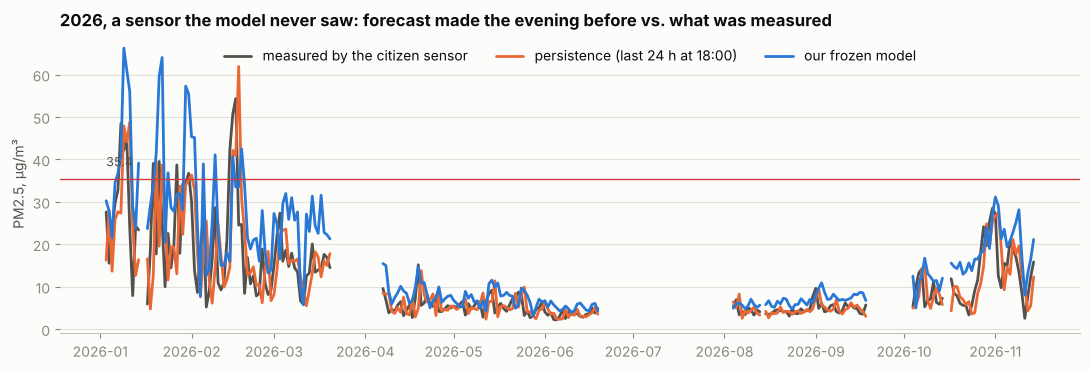

In [25]:
ext_by_day = external.set_index("target_date")[["target", "persistence", "model"]]
ext_by_day = ext_by_day.reindex(pd.date_range(ext_by_day.index.min(), ext_by_day.index.max(), freq="D"))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(ext_by_day["target"], color=INK2, label="measured by the citizen sensor")
ax.plot(ext_by_day["persistence"], color=ORANGE, label="persistence (last 24 h at 18:00)")
ax.plot(ext_by_day["model"], color=BLUE, label="our frozen model")
ax.axhline(ALERT_LEVEL, color=RED, linewidth=1)
ax.text(ext_by_day.index.min(), ALERT_LEVEL + 3, "35.4", color=INK2, fontsize=9)
ax.set_ylabel("PM2.5, µg/m³")
ax.set_title("2026, a sensor the model never saw: forecast made the evening before vs. what was measured")
ax.legend(loc="upper center", ncol=3)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/05_external_2026.png", dpi=160)
plt.show()

## 11. Where it fails
The five Oct-Mar test days with the largest error, and how the error depends on the kind of day.

In [26]:
worst = winter_test.assign(error=winter_test["model"] - winter_test["target"])
worst = worst.reindex(worst["error"].abs().sort_values(ascending=False).index).head(5)
worst_table = worst[["target_date", "pm_last24", "model", "target", "error", "persistence", "kind", "t_mean_tmrw",
                     "wind_mean_tmrw", "precip_tmrw", "humidity_tmrw"]].rename(columns={
    "target_date": "day", "pm_last24": "last 24 h", "model": "forecast", "target": "measured", "t_mean_tmrw": "temp °C",
    "wind_mean_tmrw": "wind m/s", "precip_tmrw": "precip mm", "humidity_tmrw": "humidity %"})
worst_table

,day,last 24 h,forecast,measured,error,persistence,kind,temp °C,wind m/s,precip mm,humidity %
issue_day,,,,,,,,,,,
2025-02-01,2025-02-02,20.42,40.96,97.50,-56.54,20.42,1. smog starts (clean -> bad),-9.12,0.79,0.0,85.88
2024-12-22,2024-12-23,41.38,51.35,107.04,-55.69,41.38,2. smog continues (bad -> bad),-9.50,1.27,0.0,78.71
2025-02-02,2025-02-03,79.21,69.18,124.54,-55.37,79.21,2. smog continues (bad -> bad),-9.19,1.69,0.0,78.12
2024-12-24,2024-12-25,96.29,81.65,129.42,-47.76,96.29,2. smog continues (bad -> bad),-8.85,0.78,0.0,80.46
2025-01-14,2025-01-15,119.96,69.97,23.25,46.72,119.96,3. air clears (bad -> clean),-2.34,1.00,0.0,67.92


In [27]:
high = winter_test[winter_test["target"] > 100]
print(f"Days above 100 µg/m³ in the Oct-Mar test period: {len(high)}. On these days the model's forecast was on average "
      f"{(high['model'] - high['target']).mean():.0f} µg/m³ away from the measurement (negative = too low); "
      f"persistence: {(high['persistence'] - high['target']).mean():.0f}.")
month_errors = winter_test.groupby(winter_test["target_date"].dt.to_period("M")).apply(
    lambda g: pd.Series({"days": len(g), "measured average": g["target"].mean(),
                         "model error": mae(g["target"], g["model"]), "persistence error": mae(g["target"], g["persistence"])}))
month_errors

Days above 100 µg/m³ in the Oct-Mar test period: 11. On these days the model's forecast was on average -35 µg/m³ away from the measurement (negative = too low); persistence: -21.


,days,measured average,model error,persistence error
target_date,,,,
2024-10,21.0,18.32,6.16,8.69
2024-11,30.0,29.36,7.82,10.68
2024-12,31.0,50.67,18.49,24.65
2025-01,31.0,51.07,17.27,30.08
2025-02,28.0,74.75,20.22,24.69
2025-03,31.0,27.15,8.45,10.97
2025-10,31.0,25.44,6.54,7.21
2025-11,13.0,22.96,9.37,16.76


## 12. Why does the model say what it says?
Ridge regression is a weighted sum, so every forecast can be split into pieces. We group the inputs into a few
plain-language reasons and show how strongly each one moves the forecast on a typical day.

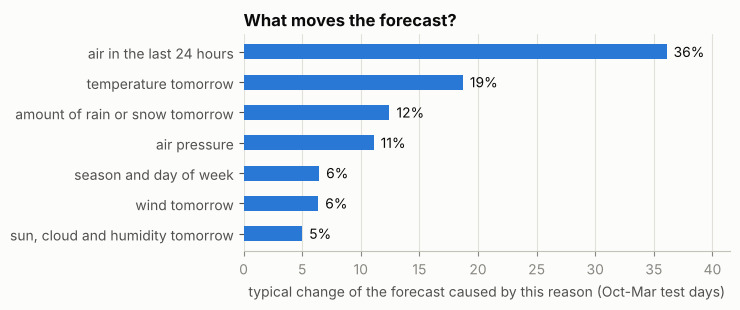

In [28]:
REASONS = {
    "air in the last 24 hours": PM_COLS,
    "temperature tomorrow": ["t_mean_tmrw", "t_min_tmrw", "t_mean_change"],
    "wind tomorrow": ["wind_mean_tmrw", "wind_max_tmrw", "gust_max_tmrw", "wind_u_tmrw", "wind_v_tmrw", "wind_mean_change"],
    "amount of rain or snow tomorrow": ["precip_tmrw", "snowfall_tmrw"],
    "sun, cloud and humidity tomorrow": ["sun_tmrw", "cloud_tmrw", "humidity_tmrw"],
    "air pressure": ["pressure_tmrw", "pressure_change"],
    "season and day of week": CALENDAR_COLS,
}
assert sorted(sum(REASONS.values(), [])) == sorted(FEATURES)       # every input belongs to exactly one reason


def reasons_for(df):
    """For each row: how much each group of inputs pushes the forecast up or down (on the log scale),
    compared with an average training day."""
    scaler, ridge = final_model[0], final_model[1]
    pieces = pd.DataFrame(scaler.transform(prepare(df, FEATURES)) * ridge.coef_, index=df.index, columns=FEATURES)
    return pd.DataFrame({name: pieces[cols].sum(axis=1) for name, cols in REASONS.items()})


typical = reasons_for(winter_test).abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.2))
bars = ax.barh(typical.index, (np.exp(typical) - 1) * 100, height=0.5, color=BLUE)
for bar in bars:
    ax.text(bar.get_width() + 0.6, bar.get_y() + bar.get_height() / 2, f"{bar.get_width():.0f}%", va="center", color=INK, fontsize=10)
ax.set_xlim(0, float((np.exp(typical.max()) - 1) * 100) * 1.15)
ax.set_xlabel("typical change of the forecast caused by this reason (Oct-Mar test days)")
ax.set_title("What moves the forecast?")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", colors=INK2)
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/04_reasons.png", dpi=160)
plt.show()

## 13. Demo: the message the teacher sees
Pick any evening from the locked test period. The forecast uses only what was known at 18:00 that evening;
then we reveal what was measured the next day. (The monitor's public archive ends in November 2025, so this is a
replay of held-out days, not a live reading.)

In [29]:
CATEGORIES = [(9.0, "Good", "Хорошо"), (35.4, "Moderate", "Умеренно"),
              (55.4, "Unhealthy for sensitive groups", "Вредно для чувствительных групп"),
              (125.4, "Unhealthy", "Вредно"), (225.4, "Very unhealthy", "Очень вредно"),
              (float("inf"), "Hazardous", "Опасно")]
# US EPA PM2.5 24-hour categories, 2024 update:
# https://www.epa.gov/system/files/documents/2024-02/pm-naaqs-air-quality-index-fact-sheet.pdf
TEXT = {
    "en": dict(made="Forecast made", for_day="for", value="Tomorrow's PM2.5", about="about", range="likely range",
               category="Air category", advice="Advice for PE", indoors="plan the lesson INDOORS",
               unsure="outdoors is likely fine, but check the morning reading", outdoors="OUTDOORS is fine",
               why="Main reasons", up="pushes PM2.5 up", down="pushes PM2.5 down",
               truth="What was measured the next day", right="the advice was right",
               miss="MISSED: the day was bad, no warning", false="FALSE ALARM: the day was fine"),
    "ru": dict(made="Прогноз сделан", for_day="на", value="PM2.5 завтра", about="около", range="вероятный диапазон",
               category="Категория воздуха", advice="Совет для урока физкультуры", indoors="планируйте урок В ЗАЛЕ",
               unsure="скорее всего можно на улице, но проверьте показания утром", outdoors="можно НА УЛИЦЕ",
               why="Главные причины", up="повышает PM2.5", down="понижает PM2.5",
               truth="Что измерили на следующий день", right="совет оказался верным",
               miss="ПРОПУСК: день был плохим, предупреждения не было", false="ЛОЖНАЯ ТРЕВОГА: день был нормальным"),
}
REASONS_RU = {"air in the last 24 hours": "воздух за последние 24 часа", "temperature tomorrow": "температура завтра",
              "wind tomorrow": "ветер завтра", "amount of rain or snow tomorrow": "количество осадков завтра",
              "sun, cloud and humidity tomorrow": "солнце, облачность и влажность завтра",
              "air pressure": "атмосферное давление", "season and day of week": "сезон и день недели"}


def forecast_card(issue_day, lang="en", reveal=True, rows=None):
    """The message for one evening. `rows` is a table of evenings with all inputs (default: the test period)."""
    rows = test if rows is None else rows
    row = rows.loc[[pd.Timestamp(issue_day)]]
    t = TEXT[lang]
    value = float(predict(final_model, row, FEATURES)[0])
    low, high = (float(x[0]) for x in likely_range([value], row["target_date"]))
    category = next(c for c in CATEGORIES if value <= c[0])[1 if lang == "en" else 2]
    warn = value >= CUTOFF_MODEL
    advice = t["indoors"] if warn else (t["unsure"] if high > ALERT_LEVEL else t["outdoors"])
    pieces = reasons_for(row).iloc[0]
    top = pieces.reindex(pieces.abs().sort_values(ascending=False).index).head(3)
    why = "; ".join(f"{name if lang == 'en' else REASONS_RU[name]} — {t['up'] if v > 0 else t['down']} ({(np.exp(v) - 1) * 100:+.0f}%)"
                    for name, v in top.items())
    date_format = "%d %b %Y" if lang == "en" else "%d.%m.%Y"
    lines = [f"{t['made']}: {pd.Timestamp(issue_day).strftime(date_format)}, 18:00  →  {t['for_day']} {row['target_date'].iloc[0].strftime(date_format)}",
             f"{t['value']}: {t['about']} {value:.0f} µg/m³ ({t['range']} {low:.0f}–{high:.0f})",
             f"{t['category']}: {category}",
             f"{t['advice']}: {advice}",
             f"{t['why']}: {why}"]
    if reveal:
        measured = float(row["target"].iloc[0])
        bad = measured > ALERT_LEVEL
        verdict = t["right"] if warn == bad else (t["miss"] if bad else t["false"])
        lines.append(f"{t['truth']}: {measured:.0f} µg/m³ → {verdict}")
    return "\n".join(lines)


# three evenings chosen by rule, not by hand: the first test day on which smog starts (whether we caught it or not),
# the first day that stays clean, and the day with the largest error
examples = {
    "The first day in the test period on which smog starts": winter_test[winter_test["kind"].str.startswith("1.")].index[0],
    "The first day that stays clean": winter_test[winter_test["kind"].str.startswith("4.")].index[0],
    "The largest error in the test period": worst.index[0],
}
for title, day in examples.items():
    print(f"=== {title} ===\n{forecast_card(day, 'en')}\n")
print("=== The first card as the teacher would read it (Russian) ===")
print(forecast_card(list(examples.values())[0], "ru"))

=== The first day in the test period on which smog starts ===
Forecast made: 12 Nov 2024, 18:00  →  for 13 Nov 2024
Tomorrow's PM2.5: about 20 µg/m³ (likely range 10–28)
Air category: Moderate
Advice for PE: OUTDOORS is fine
Main reasons: amount of rain or snow tomorrow — pushes PM2.5 down (-38%); temperature tomorrow — pushes PM2.5 up (+13%); wind tomorrow — pushes PM2.5 up (+9%)
What was measured the next day: 36 µg/m³ → MISSED: the day was bad, no warning

=== The first day that stays clean ===
Forecast made: 10 Oct 2024, 18:00  →  for 11 Oct 2024
Tomorrow's PM2.5: about 22 µg/m³ (likely range 11–32)
Air category: Moderate
Advice for PE: OUTDOORS is fine
Main reasons: air pressure — pushes PM2.5 up (+12%); amount of rain or snow tomorrow — pushes PM2.5 up (+8%); temperature tomorrow — pushes PM2.5 down (-7%)
What was measured the next day: 11 µg/m³ → the advice was right

=== The largest error in the test period ===
Forecast made: 01 Feb 2025, 18:00  →  for 02 Feb 2025
Tomorrow's PM

### Optional: a small web page for the demo (Gradio)
Set `RUN_APP = True` to open a page with a date picker (works in Google Colab). The same page is in `app.py`.

In [30]:
RUN_APP = False
if RUN_APP:
    import gradio as gr

    def show(day, language):
        return forecast_card(day, "ru" if language == "Русский" else "en")

    days = [d.strftime("%Y-%m-%d") for d in winter_test.index]
    gr.Interface(show, [gr.Dropdown(days, value=days[0], label="Evening (18:00) in the held-out test period"),
                        gr.Radio(["English", "Русский"], value="English", label="Language")],
                 gr.Textbox(lines=8, label="Forecast for the next day"), title="Smog Tomorrow? — Almaty",
                 description="Replay of held-out days: the forecast uses only what was known at 18:00 that evening.").launch()

## Save the results
Everything quoted in the write-up comes from these files.

In [31]:
scaler, ridge = final_model[0], final_model[1]
with open(f"{RESULTS_DIR}/model.json", "w") as f:
    json.dump({"features": FEATURES, "log_columns": [c for c in FEATURES if c in SKEWED],
               "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(), "coef": ridge.coef_.tolist(),
               "intercept": float(ridge.intercept_), "cutoff": CUTOFF_MODEL, "alert_level": ALERT_LEVEL,
               "likely_range_log": RANGE, "reasons": REASONS}, f, indent=1)
test.assign(warn_model=test["model"] >= CUTOFF_MODEL).to_csv(f"{RESULTS_DIR}/predictions_test.csv", float_format="%.3f")
external.assign(warn_model=external["model"] >= CUTOFF_MODEL).to_csv(f"{RESULTS_DIR}/predictions_2026_citizen_sensor.csv", float_format="%.3f")
metrics = {
    "test_period": [str(test["target_date"].min().date()), str(test["target_date"].max().date())],
    "test_days": len(test), "test_days_oct_mar": len(winter_test),
    "train_days_final_model": len(train_and_val),
    "mae": test_scores[["MAE Oct-Mar", "MAE all days"]].round(2).to_dict("index"),
    "gain_vs_persistence_oct_mar": {"mean": round(float(gain.mean()), 2), "ci95": [round(float(x), 2) for x in ci]},
    "gain_vs_calendar_persistence_oct_mar": {"mean": round(float(gain_tough.mean()), 2), "ci95": [round(float(x), 2) for x in ci_tough]},
    "alerts_oct_mar": alerts.to_dict("index"),
    "cutoffs": {"model": CUTOFF_MODEL, "persistence": CUTOFF_PERSISTENCE},
    "by_kind_of_day": by_kind.round(2).to_dict("index"),
    "range_coverage": {"oct_mar": round(float(inside.mean()), 3),
                       "all_days": round(float(((test["target"] >= test["range_low"]) & (test["target"] <= test["range_high"])).mean()), 3)},
    "likely_range_log": RANGE,
    "real_forecast_check": real_forecast_table.round(2).to_dict("index"),
    "model_selection_past_winters": selection.round(2).to_dict("index"),
    "timetable_validation": timetable_validation.round(2).to_dict("index"),
    "timetable_test": timetable_test.round(2).to_dict("index"),
    "cams_check_test": {"cutoff_tuned_on_validation": CUTOFF_CAMS, "table": cams_table.round(2).to_dict("index"),
                        "model_gain_vs_cams_oct_mar": {"mean": round(float(cams_gain.mean()), 2), "ci95": [round(float(x), 2) for x in cams_ci]}},
    "school_hours_check_test": {"days": int(len(winter_school)),
                                "mean_whole_day": round(float(winter_school["target"].mean()), 2),
                                "mean_school_hours": round(float(winter_school["school"].mean()), 2),
                                "bad_by_whole_day": int((winter_school["target"] > ALERT_LEVEL).sum()),
                                "bad_by_school_hours": int((winter_school["school"] > ALERT_LEVEL).sum()),
                                "alerts": school_alerts.to_dict("index"),
                                "timetable_school_hours_air": {k: {kk: round(vv, 2) for kk, vv in v.items()} for k, v in school_timetable.items()}},
    "external_2026": {"sensor": "sensor.community SDS011 no. 78340 (citizen sensor, central Almaty)",
                      "protocol_commit": "dd8b550",
                      "period": [str(external["target_date"].min().date()), str(external["target_date"].max().date())],
                      "days": int(len(external)), "days_oct_mar": int(len(ext_winter)),
                      "bad_days_oct_mar": int((ext_winter["target"] > ALERT_LEVEL).sum()),
                      "table": ext_table.round(2).to_dict("index"),
                      "gain_vs_persistence_oct_mar": {"mean": round(float(ext_gain.mean()), 2), "ci95": [round(float(x), 2) for x in ext_ci]},
                      "gain_vs_persistence_all_days": {"mean": round(float(ext_gain_all.mean()), 2), "ci95": [round(float(x), 2) for x in ext_ci_all]},
                      "range_coverage_oct_mar": round(float(ext_inside.mean()), 3),
                      "by_kind_of_day": ext_by_kind.round(2).to_dict("index"),
                      "timetable": ext_timetable.round(2).to_dict("index"),
                      "timetable_quota2": {"weeks": int(len(ext_saved)), "cleaner_than_fixed": round(float(ext_saved.mean()), 2),
                                           "ci95_vs_fixed": [round(float(x), 2) for x in ext_ci_fixed],
                                           "cleaner_than_persistence_planner": round(float(ext_saved_vs_persistence.mean()), 2),
                                           "ci95_vs_persistence": [round(float(x), 2) for x in ext_ci_pers]}},
    "library_versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                         "scikit-learn": sklearn.__version__},
    "timetable_test_quota2": {"weeks": int(len(saved)), "cleaner_than_fixed": round(float(saved.mean()), 2),
                              "ci95_vs_fixed": [round(float(x), 2) for x in ci_fixed],
                              "cleaner_than_persistence_planner": round(float(saved_vs_persistence.mean()), 2),
                              "ci95_vs_persistence": [round(float(x), 2) for x in ci_pers],
                              "weeks_better_tied_worse": [int((saved > 0.05).sum()), int((np.abs(saved) <= 0.05).sum()), int((saved < -0.05).sum())]},
}
with open(f"{RESULTS_DIR}/metrics.json", "w") as f:
    json.dump(metrics, f, indent=1, default=str)
print("saved:", sorted(os.listdir(RESULTS_DIR)))

saved: ['figures', 'metrics.json', 'model.json', 'predictions_2026_citizen_sensor.csv', 'predictions_test.csv']


## Honest notes
* **One monitor, one city.** The monitor is one point in Almaty; other districts can differ.
* **Not live.** The public archive of the reference monitor ends on 14 November 2025, so the demo replays
  held-out days. Section 10 checks the frozen model on 2026 with a citizen sensor instead.
* **Weather inputs.** The main test uses the weather model's record of the day (as if the forecast were perfect);
  section 7 shows what changes with real archived forecasts.
* **Small data.** The final model is trained on 886 evenings; the early years have many gaps.
* **One early look.** Before the rules were fixed, a quick correlation check was run on all years, including
  the test period. No input was added or removed because of it; all later choices used older data only.
* **The timetable was added later.** Section 8 was written after the forecast test had been run. Its rule has no
  tuned numbers and was tried on the validation year first; the forecasting model was not changed for it.
* **Checks added later.** Sections 9 and 10 were written after the forecast test. Section 9 looks at the same
  test days again without changing the model. Section 10 uses new 2026 data under rules committed before the run.
  The rule was "every day in the sensor archive"; our note guessed that the archive starts on 15 January, but it
  starts on 1 January, so the earlier days are included and the 15-January-only result is printed next to it.
* **Today's weather.** The "change from today" inputs use the weather model's record of the whole of today,
  including the six hours after 18:00. In real use those hours would be a six-hour forecast.
* **Not medical advice.** The warning level is the US EPA 24-hour boundary; a school should set its own rule.